# Automobile Data Analysis

**Author:** MARISON EMILE

## Project Overview

This project explores an automobile dataset to identify relationships between vehicle characteristics and price. Using Python, Pandas, NumPy, and Matplotlib, the analysis covers data cleaning, descriptive statistics, correlation analysis, and data visualization.

## Project Objectives

* Load and inspect the automobile dataset.
* Identify and handle missing values.
* Explore automobile price distributions.
* Analyze relationships between price and selected vehicle characteristics.
* Summarize key findings using statistical results and visualizations.

## Tools and Technologies

* Python
* Pandas
* NumPy
* Matplotlib
* Google Colab

## Dataset Overview

The dataset initially contains 205 rows and 26 columns. After removing four records with missing prices and handling the remaining missing values, the cleaned dataset contains 201 rows and 26 columns.

## Data Cleaning

Missing-value markers represented by `?` were replaced with missing values. Records without a valid price were removed. Missing numerical values in selected columns were imputed using their median values, while missing values in the `num-of-doors` column were filled using the mode.

The cleaned dataset was checked to confirm that no missing values remained.


In [1]:
import pandas as pd
import numpy as np

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/auto.csv"

df = pd.read_csv(url, header=None)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (205, 26)


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [2]:
print("First 5 rows:")
display(df.head())

print("Dataset information:")
df.info()

print("Missing values per column:")
print(df.isnull().sum())

First 5 rows:


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       205 non-null    int64  
 1   1       205 non-null    object 
 2   2       205 non-null    object 
 3   3       205 non-null    object 
 4   4       205 non-null    object 
 5   5       205 non-null    object 
 6   6       205 non-null    object 
 7   7       205 non-null    object 
 8   8       205 non-null    object 
 9   9       205 non-null    float64
 10  10      205 non-null    float64
 11  11      205 non-null    float64
 12  12      205 non-null    float64
 13  13      205 non-null    int64  
 14  14      205 non-null    object 
 15  15      205 non-null    object 
 16  16      205 non-null    int64  
 17  17      205 non-null    object 
 18  18      205 non-null    object 
 19  19      205 non-null    object 
 20  20      205 non-null    float64
 21  21      205 non-nu

In [3]:
headers = [
    "symboling", "normalized-losses", "make", "fuel-type",
    "aspiration", "num-of-doors", "body-style", "drive-wheels",
    "engine-location", "wheel-base", "length", "width",
    "height", "curb-weight", "engine-type", "num-of-cylinders",
    "engine-size", "fuel-system", "bore", "stroke",
    "compression-ratio", "horsepower", "peak-rpm",
    "city-mpg", "highway-mpg", "price"
]

df.columns = headers

print("Column names updated successfully!")
display(df.head())

Column names updated successfully!


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [4]:
# Count unknown values represented by "?"
(df == "?").sum()

,0
symboling,0
normalized-losses,41
make,0
fuel-type,0
aspiration,0
num-of-doors,2
body-style,0
drive-wheels,0
engine-location,0
wheel-base,0


In [5]:
import numpy as np

df.replace("?", np.nan, inplace=True)

print("Unknown values converted to NaN.")
print("\nMissing values per column:")
print(df.isnull().sum())

Unknown values converted to NaN.

Missing values per column:
symboling             0
normalized-losses    41
make                  0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 4
dtype: int64


In [6]:
df.dropna(subset=["price"], inplace=True)

print("Dataset shape after removing rows without price:")
print(df.shape)

print("\nMissing values per column:")
print(df.isnull().sum())

Dataset shape after removing rows without price:
(201, 26)

Missing values per column:
symboling             0
normalized-losses    37
make                  0
fuel-type             0
aspiration            0
num-of-doors          2
body-style            0
drive-wheels          0
engine-location       0
wheel-base            0
length                0
width                 0
height                0
curb-weight           0
engine-type           0
num-of-cylinders      0
engine-size           0
fuel-system           0
bore                  4
stroke                4
compression-ratio     0
horsepower            2
peak-rpm              2
city-mpg              0
highway-mpg           0
price                 0
dtype: int64


In [7]:
numeric_columns = [
    "normalized-losses",
    "bore",
    "stroke",
    "horsepower",
    "peak-rpm"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")
    median_value = df[column].median()
    df[column] = df[column].fillna(median_value)

print("Missing values after median imputation:")
print(df[numeric_columns].isnull().sum())

Missing values after median imputation:
normalized-losses    0
bore                 0
stroke               0
horsepower           0
peak-rpm             0
dtype: int64


In [8]:
print(df["num-of-doors"].value_counts(dropna=False))

num-of-doors
four    113
two      86
NaN       2
Name: count, dtype: int64


In [9]:
mode_value = df["num-of-doors"].mode()[0]

df["num-of-doors"] = df["num-of-doors"].fillna(mode_value)

print("Missing values in num-of-doors:",
      df["num-of-doors"].isnull().sum())

print("Most common number of doors:", mode_value)

Missing values in num-of-doors: 0
Most common number of doors: four


In [10]:
print("Dataset shape:", df.shape)

print("\nMissing values in the entire dataset:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Dataset shape: (201, 26)

Missing values in the entire dataset:
symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
dtype: int64

Total missing values:
0


In [11]:
# Convert price to numeric values
df["price"] = pd.to_numeric(df["price"], errors="coerce")

# Calculate descriptive statistics
print("Car Price Statistics")
print(df["price"].describe())

Car Price Statistics
count      201.000000
mean     13207.129353
std       7947.066342
min       5118.000000
25%       7775.000000
50%      10295.000000
75%      16500.000000
max      45400.000000
Name: price, dtype: float64


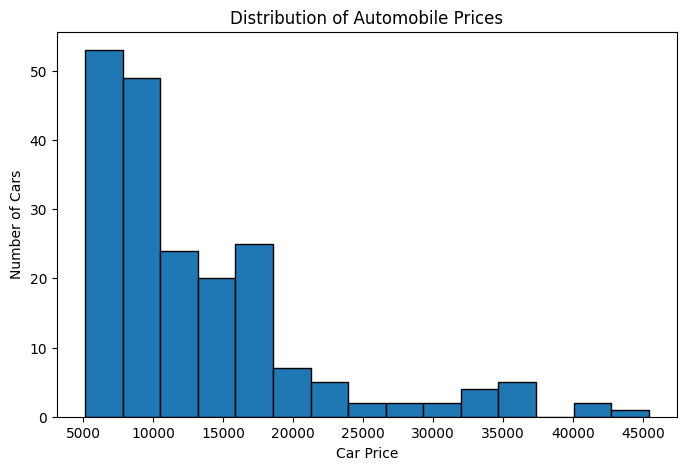

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["price"], bins=15, edgecolor="black")

plt.xlabel("Car Price")
plt.ylabel("Number of Cars")
plt.title("Distribution of Automobile Prices")

plt.show()

### Finding 1: Distribution of Automobile Prices

The histogram shows that most automobiles in the dataset are concentrated in the lower price ranges, particularly around 5,000 to 11,000. The number of cars generally decreases as prices increase. The distribution is right-skewed, indicating that a smaller number of high-priced automobiles extend the distribution toward higher values.

The mean price (13,207.13) is higher than the median price (10,295), which is consistent with the presence of relatively expensive automobiles in the dataset.

**Conclusion:** Automobile prices are not evenly distributed. Most cars have comparatively lower prices, while a smaller group of expensive cars contributes to the higher end of the distribution.


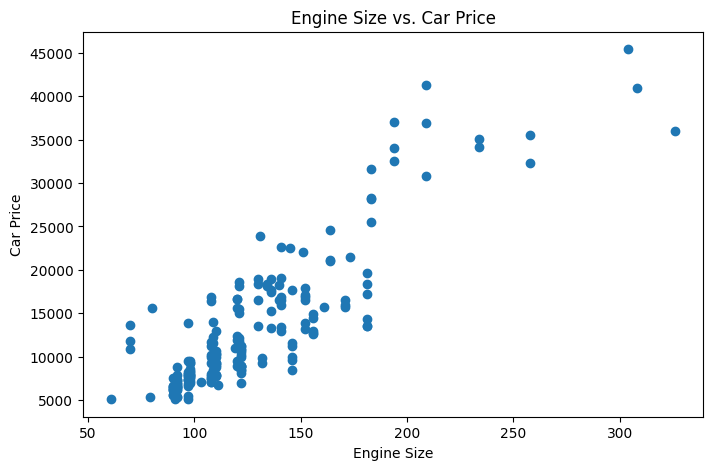

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(df["engine-size"], df["price"])

plt.xlabel("Engine Size")
plt.ylabel("Car Price")
plt.title("Engine Size vs. Car Price")

plt.show()

In [14]:
print(df[["engine-size", "price"]].corr())

             engine-size     price
engine-size     1.000000  0.872335
price           0.872335  1.000000


### Finding 2: Relationship Between Engine Size and Car Price

The correlation coefficient between engine size and car price is approximately **0.8723**, indicating a strong positive linear relationship.

This suggests that automobiles with larger engines tend to have higher prices in this dataset. However, correlation does not prove causation, and other factors may also influence vehicle prices.

**Conclusion:** Engine size is strongly associated with automobile price and may be a useful feature for price analysis.


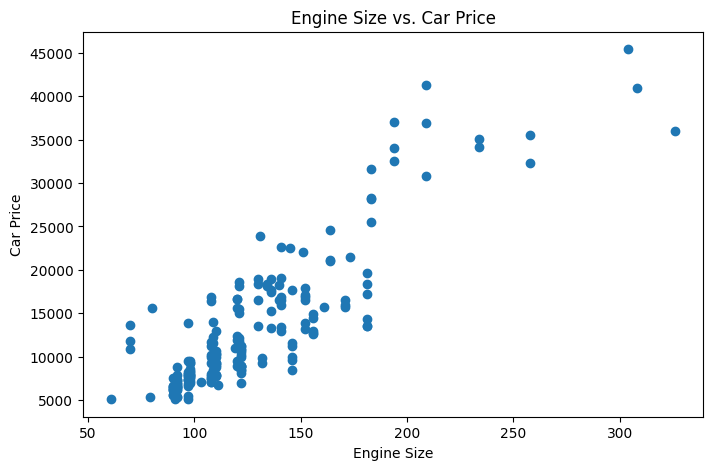

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df["engine-size"], df["price"])
plt.xlabel("Engine Size")
plt.ylabel("Car Price")
plt.title("Engine Size vs. Car Price")
plt.show()

In [16]:
print("Correlation:", df["engine-size"].corr(df["price"]))

print("\nAverage price by engine size:")
print(
    df.groupby(
        pd.cut(df["engine-size"], bins=4),
        observed=True
    )["price"].mean().round(2)
)

Correlation: 0.8723351674455198

Average price by engine size:
engine-size
(60.735, 127.25]     9081.40
(127.25, 193.5]     17004.58
(193.5, 259.75]     34957.90
(259.75, 326.0]     40786.67
Name: price, dtype: float64


In [17]:
print(
    df.groupby("body-style")["price"]
      .mean()
      .sort_values(ascending=False)
      .round(2)
)

body-style
hardtop        22208.50
convertible    21890.50
sedan          14459.76
wagon          12371.96
hatchback       9957.44
Name: price, dtype: float64


### Finding 4: Average Car Price by Body Style

The analysis shows that hardtop automobiles have the highest average price at 22,208.50, followed by convertibles at 21,890.50. Sedans have an average price of 14,459.76, while wagons average 12,371.96. Hatchbacks have the lowest average price at 9,957.44.

**Conclusion:** Average automobile prices vary across body styles. Hardtops and convertibles have higher average prices in this dataset, whereas hatchbacks have the lowest average price. These results describe this dataset and do not necessarily represent the entire automobile market.


In [18]:
print(
    df.groupby("fuel-type")["price"]
      .mean()
      .sort_values(ascending=False)
      .round(2)
)

fuel-type
diesel    15838.15
gas       12916.41
Name: price, dtype: float64


In [21]:
print("Correlation between Highway MPG and Price:")
print(df["highway-mpg"].corr(df["price"]))

print("\nAverage price by highway MPG:")
print(
    df.groupby(
        pd.cut(df["highway-mpg"], bins=4),
        observed=True
    )["price"].mean().round(2)
)

Correlation between Highway MPG and Price:
-0.704692265058953

Average price by highway MPG:
highway-mpg
(15.962, 25.5]    21311.02
(25.5, 35.0]      11196.62
(35.0, 44.5]       7285.05
(44.5, 54.0]       7146.43
Name: price, dtype: float64


### Finding 6: Relationship Between Highway Fuel Efficiency and Car Price

The correlation coefficient between highway fuel efficiency and car price is approximately **-0.7047**, indicating a strong negative linear relationship in this dataset.

The average price decreases from 21,311.02 in the lowest highway-MPG group to 7,146.43 in the highest highway-MPG group.

**Conclusion:** Vehicles with lower highway fuel efficiency tend to have higher prices in this dataset, while vehicles with higher highway MPG tend to have lower prices. This association does not establish causation, as other vehicle characteristics may also influence price.


### Finding 5: Average Car Price by Fuel Type

The analysis shows that diesel automobiles have an average price of 15,838.15, compared with 12,916.41 for gasoline-powered automobiles. The difference in average price is 2,921.74.

**Conclusion:** Diesel automobiles have a higher average price than gasoline-powered automobiles in this dataset. However, this difference may also reflect other vehicle characteristics, such as engine size, body style, and equipment, rather than fuel type alone.


In [22]:
print("Correlation between City MPG and Price:")
print(df["city-mpg"].corr(df["price"]))

print("\nAverage price by City MPG:")
print(
    df.groupby(
        pd.cut(df["city-mpg"], bins=4),
        observed=True
    )["price"].mean().round(2)
)

Correlation between City MPG and Price:
-0.686571006784468

Average price by City MPG:
city-mpg
(12.964, 22.0]    20966.12
(22.0, 31.0]       9557.92
(31.0, 40.0]       7537.81
(40.0, 49.0]       6243.00
Name: price, dtype: float64


In [23]:
print("Correlation between Horsepower and Price:")
print(df["horsepower"].corr(df["price"]))

print("\nAverage price by horsepower group:")
print(
    df.groupby(
        pd.cut(df["horsepower"], bins=4),
        observed=True
    )["price"].mean().round(2)
)

Correlation between Horsepower and Price:
0.8105000308467999

Average price by horsepower group:
horsepower
(47.786, 101.5]     9021.68
(101.5, 155.0]     16123.62
(155.0, 208.5]     25899.13
(208.5, 262.0]     36000.00
Name: price, dtype: float64


### Finding 7: Relationship Between City Fuel Efficiency and Car Price

The correlation coefficient between city fuel efficiency and car price is approximately **-0.6866**, indicating a strong negative linear relationship in this dataset.

The average price decreases from 20,966.12 in the lowest city-MPG group to 6,243.00 in the highest city-MPG group.

**Conclusion:** Vehicles with higher city fuel efficiency tend to have lower prices in this dataset. However, this relationship does not establish causation, and other vehicle characteristics may also contribute to price differences.


### Finding 8: Relationship Between Horsepower and Car Price

The correlation coefficient between horsepower and car price is approximately **0.8105**, indicating a strong positive linear relationship in this dataset.

The average price increases from 9,021.68 in the lowest-horsepower group to 36,000.00 in the highest-horsepower group.

**Conclusion:** Vehicles with higher horsepower tend to have higher average prices in this dataset. Horsepower may be a useful feature for understanding automobile prices, although other vehicle characteristics may also influence price.


In [24]:
print("Final dataset shape:", df.shape)

print("\nTop 5 most expensive cars:")
print(
    df[["make", "body-style", "engine-size", "horsepower", "price"]]
    .sort_values(by="price", ascending=False)
    .head()
    .to_string(index=False)
)

Final dataset shape: (201, 26)

Top 5 most expensive cars:
         make  body-style  engine-size  horsepower  price
mercedes-benz     hardtop          304       184.0  45400
          bmw       sedan          209       182.0  41315
mercedes-benz       sedan          308       184.0  40960
      porsche convertible          194       207.0  37028
          bmw       sedan          209       182.0  36880


### Finding 9: Top Five Most Expensive Automobiles

The top five most expensive vehicles in the cleaned dataset include models from Mercedes-Benz, BMW, and Porsche. The highest-priced vehicle is a Mercedes-Benz hardtop with an engine size of 304, 184 horsepower, and a price of 45,400.

Mercedes-Benz and BMW each appear twice among the top five vehicles.

**Conclusion:** The highest-priced vehicles in this dataset include premium automobile brands and relatively large engines. However, this small selection does not establish that brand or engine size alone determines automobile price.


# Final Conclusion

This project analyzed 201 automobiles using Python, Pandas, NumPy, and Matplotlib after cleaning the original dataset.

The analysis identified several important patterns:

* Automobile prices are right-skewed, with most vehicles concentrated in lower price ranges and a smaller number of expensive vehicles.
* Engine size has a strong positive correlation with price (0.8723).
* Horsepower also has a strong positive correlation with price (0.8105).
* Highway MPG (-0.7047) and city MPG (-0.6866) have negative correlations with price.
* Hardtops and convertibles have the highest average prices among the body styles analyzed.
* Diesel vehicles have a higher average price than gasoline-powered vehicles in this dataset.
* The most expensive vehicle is a Mercedes-Benz hardtop priced at 45,400.

Overall, the results suggest that engine size, horsepower, fuel efficiency, body style, and fuel type are useful characteristics to explore when analyzing automobile prices. These relationships are observational and do not establish causation.

## Skills Demonstrated

* Data loading and inspection
* Data cleaning and missing-value handling
* Descriptive statistics
* Correlation analysis
* Grouped analysis using Pandas
* Data visualization
* Analytical interpretation and reporting
